COMPARAÇÃO ENTRE DFT E FFT
Número de amostras: 64
Erro máximo entre os resultados: 2.9875026831e-13
Resultados equivalentes: True


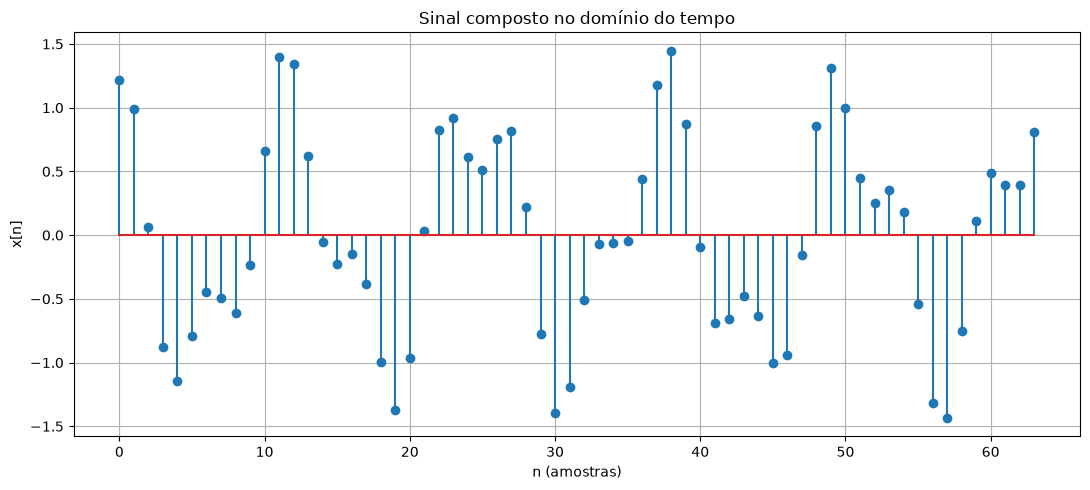

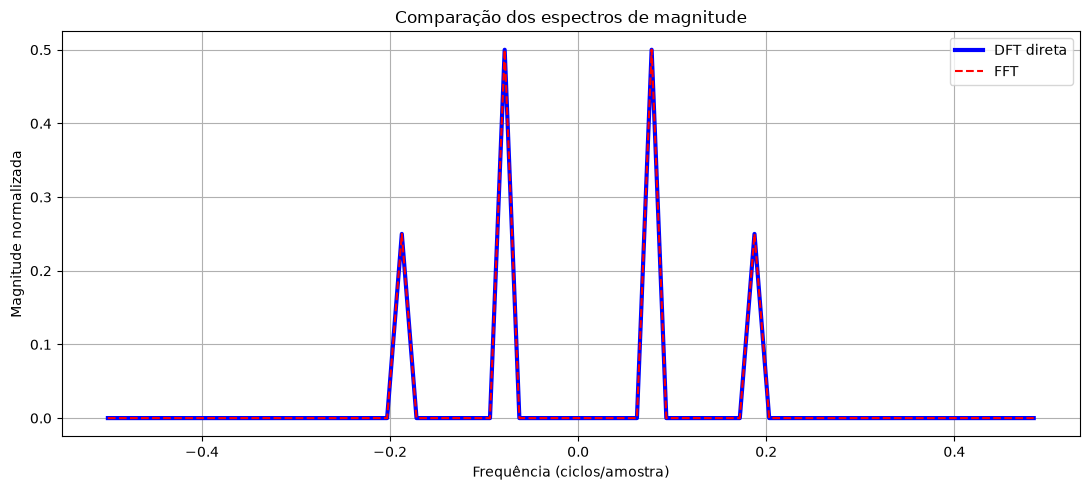

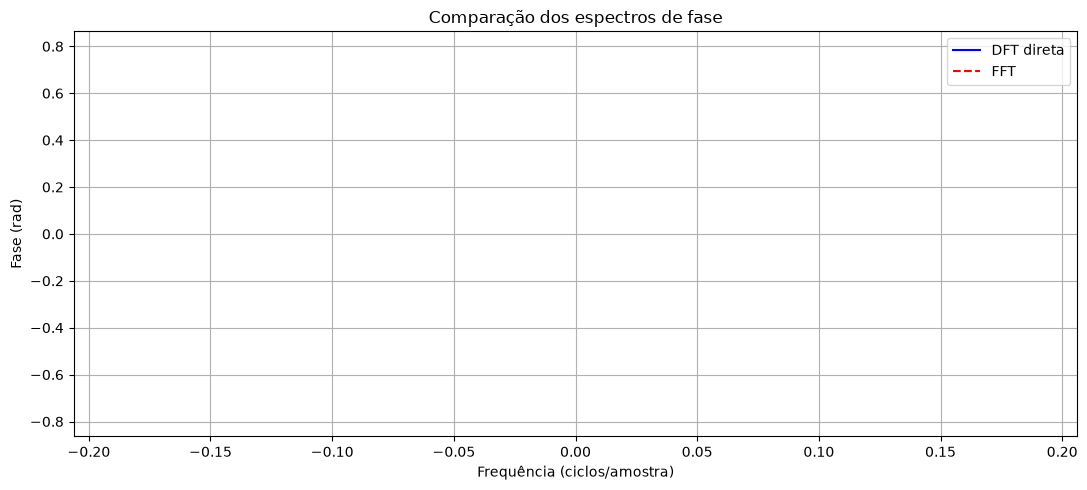


TEMPO DE EXECUÇÃO
N         DFT (ms)            FFT (ms)            
16        0.090208            0.002125            
32        0.353125            0.002167            
64        1.369833            0.002417            
128       5.568750            0.002958            
256       22.548333           0.003250            
512       92.544458           0.004459            


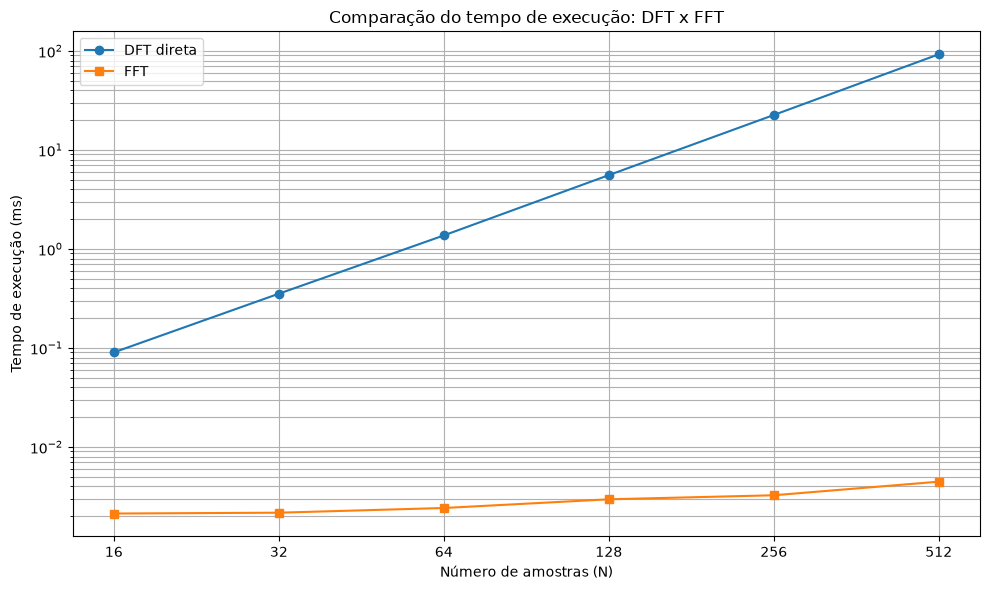


FATOR DE ACELERAÇÃO DA FFT
N = 16    FFT aproximadamente 42.45x mais rápida
N = 32    FFT aproximadamente 162.95x mais rápida
N = 64    FFT aproximadamente 566.75x mais rápida
N = 128   FFT aproximadamente 1882.61x mais rápida
N = 256   FFT aproximadamente 6937.96x mais rápida
N = 512   FFT aproximadamente 20754.47x mais rápida

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import time

# ============================================================
# 1. IMPLEMENTAÇÃO DA DFT DIRETA
# ============================================================

def calcular_dft(x):
    """
    Calcula a DFT diretamente pela definição matemática:

    X[k] = sum(x[n] * exp(-j*2*pi*k*n/N))
    """

    N = len(x)
    X = np.zeros(N, dtype=complex)

    for k in range(N):
        for n in range(N):
            X[k] += x[n] * np.exp(-1j * 2 * np.pi * k * n / N)

    return X


# ============================================================
# 2. IMPLEMENTAÇÃO DA FFT
# ============================================================

def calcular_fft(x):
    """
    Calcula a FFT utilizando a função otimizada do NumPy.
    """

    return np.fft.fft(x)


# ============================================================
# 3. GERAÇÃO DO SINAL
# ============================================================

N = 64
n = np.arange(N)

# Parâmetros da primeira senoide
A1 = 1.0
k1 = 5
phi1 = np.pi / 6

# Parâmetros da segunda senoide
A2 = 0.5
k2 = 12
phi2 = -np.pi / 4

# Frequências angulares
w1 = 2 * np.pi * k1 / N
w2 = 2 * np.pi * k2 / N

# Geração das senoides
x1 = A1 * np.cos(w1 * n + phi1)
x2 = A2 * np.cos(w2 * n + phi2)

# Sinal composto
x = x1 + x2


# ============================================================
# 4. CÁLCULO E COMPARAÇÃO DAS TRANSFORMADAS
# ============================================================

X_dft = calcular_dft(x)
X_fft = calcular_fft(x)

# Diferença entre os resultados
erro = np.abs(X_dft - X_fft)

print("COMPARAÇÃO ENTRE DFT E FFT")
print("=" * 45)

print(f"Número de amostras: {N}")
print(f"Erro máximo entre os resultados: {np.max(erro):.10e}")
print(f"Resultados equivalentes: {np.allclose(X_dft, X_fft)}")


# ============================================================
# 5. REPRESENTAÇÃO DO SINAL NO DOMÍNIO DO TEMPO
# ============================================================

plt.figure(figsize=(11, 5))

plt.stem(n, x)

plt.title("Sinal composto no domínio do tempo")
plt.xlabel("n (amostras)")
plt.ylabel("x[n]")

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. COMPARAÇÃO DOS ESPECTROS DE MAGNITUDE
# ============================================================

frequencias = np.fft.fftfreq(N)
frequencias = np.fft.fftshift(frequencias)

mag_dft = np.fft.fftshift(np.abs(X_dft) / N)
mag_fft = np.fft.fftshift(np.abs(X_fft) / N)

plt.figure(figsize=(11, 5))

plt.plot(frequencias, mag_dft, 'b-', linewidth=3,
         label="DFT direta")

plt.plot(frequencias, mag_fft, 'r--', linewidth=1.5,
         label="FFT")

plt.title("Comparação dos espectros de magnitude")
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("Magnitude normalizada")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. COMPARAÇÃO DOS ESPECTROS DE FASE
# ============================================================

fase_dft = np.angle(X_dft)
fase_fft = np.angle(X_fft)

fase_dft[np.abs(X_dft) < 1e-6] = np.nan
fase_fft[np.abs(X_fft) < 1e-6] = np.nan

fase_dft = np.fft.fftshift(fase_dft)
fase_fft = np.fft.fftshift(fase_fft)

plt.figure(figsize=(11, 5))

plt.plot(frequencias, fase_dft, 'b-',
         label="DFT direta")

plt.plot(frequencias, fase_fft, 'r--',
         label="FFT")

plt.title("Comparação dos espectros de fase")
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("Fase (rad)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. COMPARAÇÃO DO TEMPO DE EXECUÇÃO
# ============================================================

def medir_tempo(funcao, x, repeticoes):
    """
    Mede o tempo médio de execução de uma função.
    """

    tempos = []

    # Aquecimento da função
    funcao(x)

    for _ in range(repeticoes):
        inicio = time.perf_counter()

        funcao(x)

        fim = time.perf_counter()

        tempos.append(fim - inicio)

    return np.median(tempos)


# Diferentes quantidades de amostras
tamanhos = [16, 32, 64, 128, 256, 512]

tempos_dft = []
tempos_fft = []

print("\nTEMPO DE EXECUÇÃO")
print("=" * 55)
print(f"{'N':<10}{'DFT (ms)':<20}{'FFT (ms)':<20}")

for tamanho in tamanhos:

    indices = np.arange(tamanho)

    # Geração de um sinal de teste
    sinal = (
        np.cos(2 * np.pi * 5 * indices / tamanho)
        + 0.5 * np.cos(2 * np.pi * 12 * indices / tamanho)
    )

    # Menos repetições para DFT, que é mais lenta
    repeticoes_dft = 3 if tamanho <= 256 else 1

    tempo_dft = medir_tempo(
        calcular_dft, sinal, repeticoes_dft
    )

    tempo_fft = medir_tempo(
        calcular_fft, sinal, 100
    )

    tempos_dft.append(tempo_dft)
    tempos_fft.append(tempo_fft)

    print(
        f"{tamanho:<10}"
        f"{tempo_dft * 1000:<20.6f}"
        f"{tempo_fft * 1000:<20.6f}"
    )


# ============================================================
# 9. GRÁFICO DOS TEMPOS DE EXECUÇÃO
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(tamanhos, np.array(tempos_dft) * 1000,
         'o-', label="DFT direta")

plt.plot(tamanhos, np.array(tempos_fft) * 1000,
         's-', label="FFT")

plt.title("Comparação do tempo de execução: DFT x FFT")
plt.xlabel("Número de amostras (N)")
plt.ylabel("Tempo de execução (ms)")

plt.xscale("log", base=2)
plt.yscale("log")

plt.xticks(tamanhos, tamanhos)

plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()


# ============================================================
# 10. FATOR DE ACELERAÇÃO DA FFT
# ============================================================

print("\nFATOR DE ACELERAÇÃO DA FFT")
print("=" * 45)

for i, tamanho in enumerate(tamanhos):

    aceleracao = tempos_dft[i] / tempos_fft[i]

    print(
        f"N = {tamanho:<5} "
        f"FFT aproximadamente {aceleracao:.2f}x mais rápida"
    )


print("\nSimulação concluída!")
